# Unterrichtsbeispiel

[&larr; Einführung](01_FFT.ipynb)

## Motivation

In diesem Beispiel werden wir das Frequenzspektrum von zwei künstlichen Signalen bestimmen, um den Nutzen bzw. die Anwendung der **Frequenzanalyse** zu demonstrieren.

---

## Aufgabe

Um die Grundidee hinter der Fourieranalyse zu veranschaulichen, schauen wir uns zuerst die Fourierreihe eines Rechtecksignals an. In einem zweiten Schritt berechnen wir das Frequenzspektrum des Rechtecksignals mittels des FFT-Algorithmus. Das Rechtecksignal ist gut geeignet, um das Verständnis zu fördern, doch in Realität hat man es mit beliebigen Signalen zu tun. Aus diesem Grund werden wir danach ein künstliches Signal aus verschiedenen Schwingungen und Rauschen erzeugen und davon anschliessend das Frequenzspektrum berechnen.

---

### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, fft

### a) Frequenzspektrum der Rechteckfunktion

Zum Einstieg in die Frequenzanalyse wollen wir die *Fourier-Reihe* eines Rechtecksignals anschauen, da dies für das Verständnis der *Fouriertransformation* enorm hilfreich ist. Gemäss *Fourier* kann eine periodische Funktion $y(t)$ als Summe von unendlich vielen Sinus- und Kosinusschwingungen repräsentiert werden.

$$ 
\begin{align*}
y(t) &= y_0 +\sum_{k=1}^{\infty}\left[a_{k}\cos\left(\omega_k \, t\right)+b_{k}\sin\left(\omega_k \, t\right)\right] \\
&= y_0 +\sum_{k=1}^{\infty}A_{k}\cos\left(\omega_k t-\varphi_{k}\right) 
\end{align*}
$$

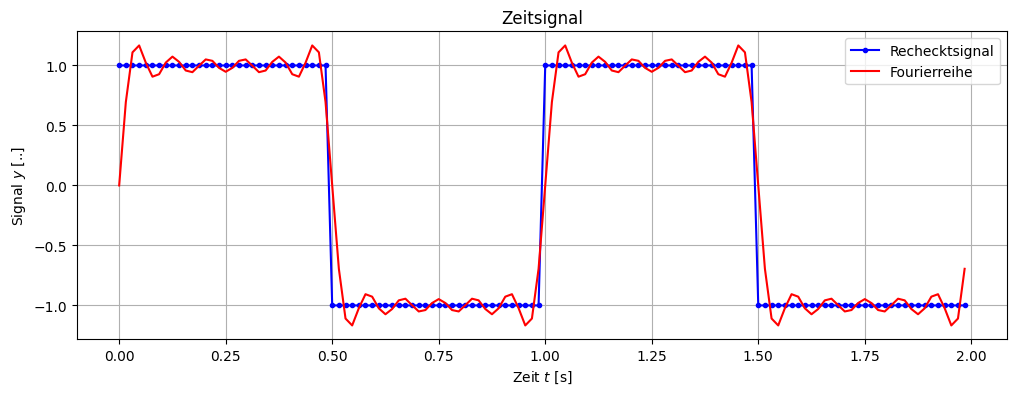

In [7]:
omega_1 = 1 * 2 * np.pi  # Frequenz Rechtecksignal (= Grundfrequenz) [rad/s]
t_meas = 2  # Zeitdauer (Messdauer) [s]
dt = 1/64  # Zeitschrittweite [s]

t = np.arange(0, t_meas, dt)  # Zeitvektor [s]
y = signal.square(omega_1 * t)  # Rechtecksignal (aus scipy.signal)

# FFT-Algorithmus wird uns die Amplituden der entsprechenden Frequenzanteile liefern
# Für das Verständnis haben wir uns überlegt, was für Frequenzen (und grob welche Amplituden)
# das Rechtecksignal "enthält" (vgl. interaktive Überlagerung von 5 Schwingungen im Unterricht)
y_fourier = 4/np.pi * (np.sin(omega_1 * t) +
                       1/3 * np.sin(3*omega_1 * t) +
                       1/5 * np.sin(5*omega_1 * t) +
                       1/7 * np.sin(7*omega_1 * t) +
                       1/9 * np.sin(9*omega_1 * t) +
                       1/11 * np.sin(11*omega_1 * t))  # würde so weitergehen
                    
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t, y, '.b-', label='Rechecktsignal')
ax.plot(t, y_fourier, 'r', label='Fourierreihe')
ax.set_title('Zeitsignal')
ax.set_xlabel('Zeit $t$ [s]')
ax.set_ylabel('Signal $y$ [..]')
ax.grid()
ax.legend()
plt.show()

SciPy stellt im Modul **fft** entsprechende Funktionen bereit, um das diskrete Frequenzspektrum (=Frequenzanteile im Signal) berechnen zu können. Basis dafür ist der FFT-Algorithmus, der eine sehr effiziente Berechnung ermöglicht. Wir verwenden für die Berechnung des Spektrums die Funktion `rfft()`, die für reelle Signale geeignet ist sowie die Funktion `rfftfreq()` für die Generierung der Frequenzachse.

Als erstes benötigen wir die Abtastfrequenz $f_S$ sowie die Sampleanzahl $N$. Kannst du diese aus den obigen Informationen bestimmen?

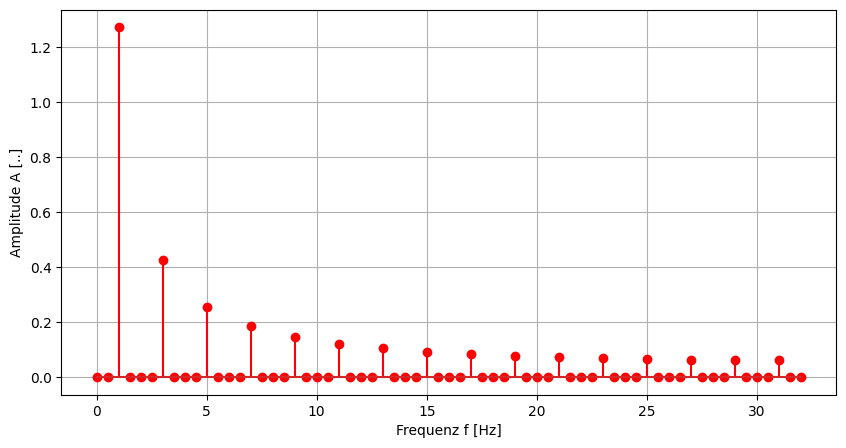

In [9]:
fs = 1/dt # Abtastfrequenz [Hz]
N = len(y)  # Anzahl Samples

Y = fft.rfft(y)/N  # Fourier-Transformation (FFT) (alternativ zu 1/N wäre das Argument norm='forward')
A = np.abs(Y)  # Amplituden (Y ist komplex, d. h. Amplitude ist Betrag davon)
A[1:] *= 2  # Alle Amplituden (ausser DC) verdoppeln (Stichwort: negative Frequenzen)
f = fft.rfftfreq(N, 1/fs)  # Frequenzachse erzeugen

fig, ax = plt.subplots(figsize=(10, 5))
ax.stem(f, A, 'r')  # alternativ plot() - hier sinnvoll, weil wir diskrete Spektrallinien haben
ax.grid()
ax.set_xlabel('Frequenz f [Hz]')
ax.set_ylabel('Amplitude A [..]')
plt.show()

### b) Frequenzspektrum einer zusammengesetzten Schwingung

Nun wollen wir das Spektrum eines realistischeren Signals berechnen (aber wiederum ein synthetisches Signal, d. h. ein Signal, das wir selber erstellen und damit genau wissen, was für Anteile es enthält.) Für eine Messdauer $t_{meas}=$ 10 s mit einer zeitlichen Auflösung von $\Delta t=$ 0.01 s soll ein Signal erzeugt werden, das aus folgenden Anteilen besteht:

- **Gleichanteil** (Offset) = 3.5
- **Sinusschwingung** mit Amplitude 2.5 und Frequenz 25 Hz
- **Sinusschwingung** mit Amplitude 1.5 und Frequenz 37 Hz
- normalverteiltes **Rauschen** mit Mittelwert = 0 und Standardabweichung = 1.25 (vgl. `random.randn()` von NumPy)

Davon soll anschliessend das Frequenzspektrum berechnet und sinnvoll dargestellt werden.

Damit wir das Signal generieren können, benötigen wir als erstes den Zeitarray. Diesen müssen wir aus den oben gegebenen Informationen (Messdauer $t_{meas}$, Abtastintervall $\Delta t$) erstellen. Kriegst du das hin?

In [13]:
t_meas = 10
dt = 0.01
fs = 1/dt
t = np.arange(0, t_meas, dt)
N = len(t)

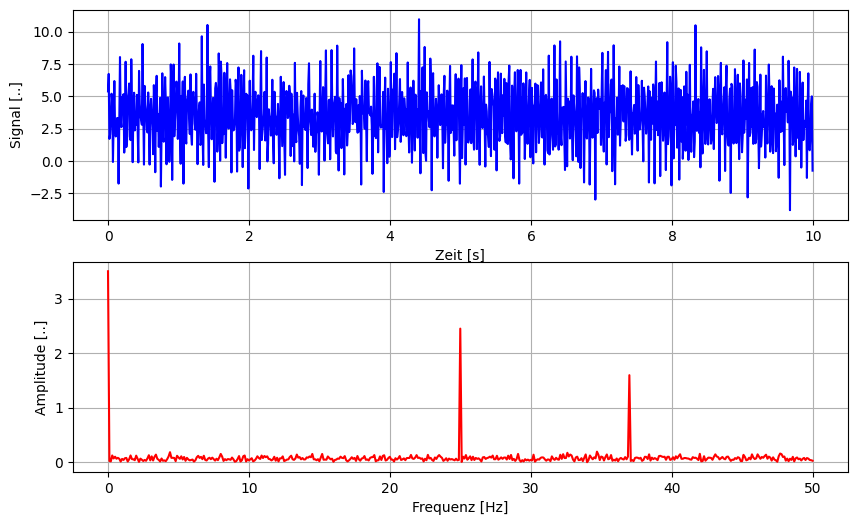

In [14]:
y = (3.5 +
     2.5 * np.sin(2*np.pi*25*t) +
     1.5 * np.sin(2*np.pi*37*t) +
     1.25 * np.random.randn(N))

Y = fft.rfft(y)/N
A = np.abs(Y)
A[1:] *= 2
f = fft.rfftfreq(N, 1/fs)

fig, axs = plt.subplots(nrows=2, figsize=(10,6))
axs[0].plot(t, y, 'b')
axs[0].grid()
axs[0].set_xlabel('Zeit [s]')
axs[0].set_ylabel('Signal [..]')
axs[1].plot(f, A, 'r')
axs[1].grid()
axs[1].set_xlabel('Frequenz [Hz]')
axs[1].set_ylabel('Amplitude [..]')
plt.show()

Erkennst du im Amplitudenspektrum die verschiedenen Anteile (Gleichanteil, Sinusschwingungen)? Woran erkennt man, dass das Signal verrauscht ist?

In [16]:
# Man erkennt die Anteile (DC, Schwingungen) sehr gut im Amplitudenspektrum,
# obwohl deutliches Rauschen vorhanden ist (im Zeitbereich ist es sehr schwierig
# die verschiedenen Frequenzanteile zu erkennen)
#
# Das Rauschen erkennt man im Amplitudenspektrum daran, dass die Amplitude bei allen
# Frequenzen unterschiedlich ist (zufällige Schwankungen). Wenn das Rauschen alle Frequenzen
# gleich betrifft, spricht man von weissem Rauschen.